# Import

In [8]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

In [9]:
X_r, X_data, u_data = gen_train_data(10,10_000,10_000)

In [10]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')
model(X_r)
model.load_weights(WEIGHT_PATH+'best_weight_MHD.h5')

solver = PINNSolver(model, batch_size = 5_000)

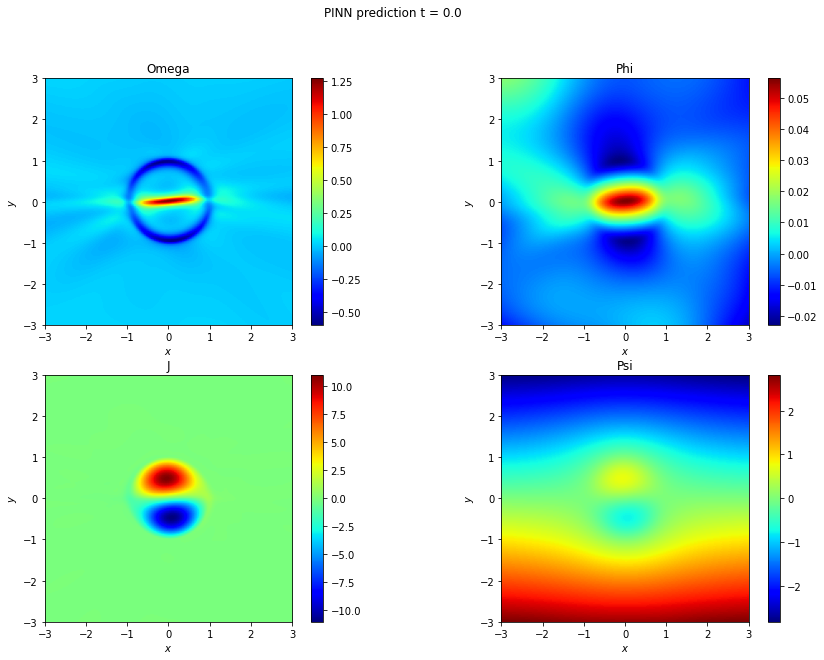

In [12]:
N = 150
t = 0.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('PINN prediction t = {}'.format(t));
plt.savefig(FIG_PATH+'MHD_PINN'+str(int(t*10)), bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)

In [ ]:
def get_residual(model, X, X_data, u_data):

    t, x, y = X[:,0:1], X[:,1:2], X[:,2:3]

    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t, x and y during this GradientTape
        tape.watch(t)
        tape.watch(x)
        tape.watch(y)

        # Compute current values u(t,x,y) and unpack variable
        u = model(tf.stack([t[:,0], x[:,0], y[:,0]], axis=1))
        omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

        phi_x = tape.gradient(phi, x)
        phi_y = tape.gradient(phi, y)

        psi_x = tape.gradient(psi, x)
        psi_y = tape.gradient(psi, y)

        omega_x = tape.gradient(omega, x)
        omega_y = tape.gradient(omega, y)

    omega_t = tape.gradient(omega, t)
    J_t = tape.gradient(J, t)

    J_x = tape.gradient(J, x)
    J_y = tape.gradient(J, y)

    omega_xx = tape.gradient(omega_x, x)
    omega_yy = tape.gradient(omega_y, y)
    psi_xx = tape.gradient(psi_x, x)
    psi_yy = tape.gradient(psi_y, y)
    phi_xx = tape.gradient(phi_x, x)
    phi_yy = tape.gradient(phi_y, y)

    phi_xy = tape.gradient(phi_x, y)
    psi_xy = tape.gradient(psi_x, x)

    del tape

    g = 2*(phi_xy*(psi_xx-psi_yy)  - psi_xy*(phi_xx-phi_yy))

    r1 = omega_t + (omega_x*phi_y - omega_y*phi_x) - (J_x*psi_y - J_y*psi_x) - viscosity*(omega_xx + omega_yy)
    r2 = phi_xx + phi_yy + omega
    r3 = J_t + (J_x*phi_y - J_y*phi_x)  - (omega_x*psi_y - omega_y*psi_x) - g - viscosity*(psi_xx + psi_yy) - viscosity*fun_J_0(x,y)
    r4 = psi_xx + psi_yy + J

    phi_r1 = tf.reduce_mean(tf.square(r1))
    phi_r2 = tf.reduce_mean(tf.square(r2))
    phi_r3 = tf.reduce_mean(tf.square(r3))
    phi_r4 = tf.reduce_mean(tf.square(r4))

    # Compute phi_0 and phi_b
    u_pred = model(X_data[0])
    phi_0 = tf.reduce_mean(tf.square(u_data[0] - u_pred))

    u_pred = model(X_data[1])
    phi_b = tf.reduce_mean(tf.square(u_data[1] - u_pred))

    return (J_x*psi_y - J_y*psi_x)
    return phi_r1, phi_r2, phi_r3, phi_r4, phi_0, phi_b

In [ ]:
y = get_residual(model, X_r, X_data, u_data)
plt.plot(y)

In [ ]:
N = 500

# compute solution using PINN
x = np.linspace(-3,3,N)
y = np.linspace(-3,3,N)
xx, yy = np.meshgrid(x, y)

r = np.sqrt(xx**2 + yy**2)
J_0 = 0.01*np.exp(-0.5*(r-1)**2/0.1)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(J_0, cmap='jet', origin='lower', extent=[-3.,3.,-3.,3.]);
fig.colorbar(img);